In [1]:
import os
import sys
import jax

In [2]:
sys.path.append('../../')

In [3]:
from modules.gt_tree_gen import *
from modules.vis_utils import *
from modules.tree_func import *

In [4]:
metadata = {
            'n_mutations':5,
            'n_all': 63,
            'n_leaves': 32,
            'n_ancestors':31,
    
            'seq_length':10,
            'n_letters':5,
            }

n_leaves = metadata['n_leaves']
n_mutations = metadata['n_mutations']

_,__, adj = generate_general_groundtruth(metadata, seed = 3)
# _,__, adj = generate_groundtruth(metadata, seed = 3)
_,__,adj



Explicitly requested dtype <class 'jax.numpy.int64'> requested in zeros is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.


(Array([[2, 3, 0, 3, 4, 4, 1, 1, 3, 0],
        [1, 4, 4, 3, 2, 1, 1, 1, 3, 0],
        [2, 0, 1, 3, 4, 0, 3, 0, 1, 3],
        [0, 0, 4, 3, 3, 1, 3, 0, 0, 0],
        [4, 3, 4, 0, 1, 2, 1, 3, 4, 1],
        [2, 3, 1, 0, 3, 3, 0, 3, 0, 3],
        [4, 4, 4, 4, 2, 0, 2, 2, 3, 3],
        [1, 4, 1, 2, 0, 3, 1, 4, 3, 0],
        [3, 4, 0, 2, 2, 1, 2, 2, 3, 1],
        [1, 0, 4, 2, 1, 2, 2, 3, 1, 3],
        [0, 0, 3, 1, 2, 4, 1, 2, 4, 4],
        [1, 0, 0, 3, 1, 1, 3, 4, 0, 3],
        [1, 1, 0, 1, 2, 2, 1, 2, 0, 0],
        [1, 0, 4, 1, 2, 2, 2, 2, 3, 2],
        [3, 2, 1, 4, 2, 2, 2, 4, 2, 4],
        [4, 4, 1, 0, 1, 0, 2, 0, 1, 4],
        [3, 0, 2, 0, 4, 2, 4, 4, 0, 0],
        [3, 2, 4, 1, 1, 2, 4, 3, 1, 4],
        [2, 4, 4, 4, 0, 2, 3, 2, 2, 0],
        [2, 2, 3, 4, 1, 0, 2, 0, 4, 0],
        [3, 4, 1, 0, 0, 4, 0, 3, 4, 2],
        [1, 4, 1, 1, 2, 1, 2, 0, 3, 0],
        [4, 4, 1, 2, 2, 3, 0, 4, 4, 4],
        [2, 1, 2, 4, 2, 4, 0, 1, 2, 0],
        [3, 3, 0, 0, 4, 4, 4, 0, 1, 0],


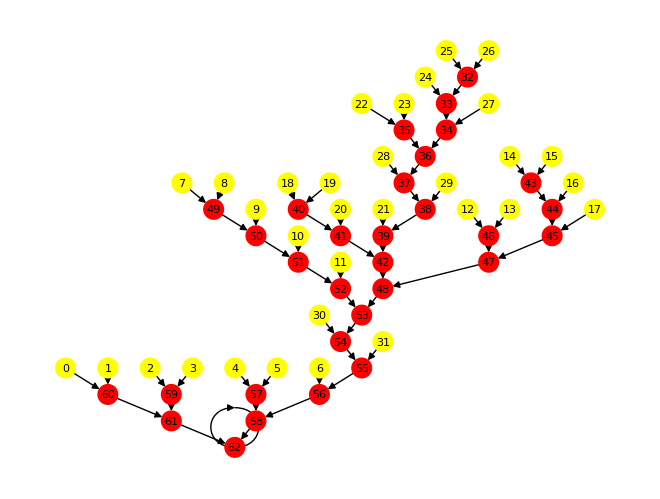

In [5]:
show_graph_with_labels(adj, n_leaves, return_img = True)

In [6]:
n_letters = metadata['n_letters']

In [7]:
sm = jnp.ones((metadata['n_letters'],metadata['n_letters'])) - jnp.identity(metadata['n_letters']).astype(jnp.float64)
gt_seqs = jax.nn.one_hot(__, n_letters).astype(jnp.float64)


Explicitly requested dtype <class 'jax.numpy.float64'> requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.


In [8]:
adj = adj.at[-1,-1].set(1)
adj

Array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]], dtype=float32)

In [9]:
__

Array([[2, 3, 0, 3, 4, 4, 1, 1, 3, 0],
       [1, 4, 4, 3, 2, 1, 1, 1, 3, 0],
       [2, 0, 1, 3, 4, 0, 3, 0, 1, 3],
       [0, 0, 4, 3, 3, 1, 3, 0, 0, 0],
       [4, 3, 4, 0, 1, 2, 1, 3, 4, 1],
       [2, 3, 1, 0, 3, 3, 0, 3, 0, 3],
       [4, 4, 4, 4, 2, 0, 2, 2, 3, 3],
       [1, 4, 1, 2, 0, 3, 1, 4, 3, 0],
       [3, 4, 0, 2, 2, 1, 2, 2, 3, 1],
       [1, 0, 4, 2, 1, 2, 2, 3, 1, 3],
       [0, 0, 3, 1, 2, 4, 1, 2, 4, 4],
       [1, 0, 0, 3, 1, 1, 3, 4, 0, 3],
       [1, 1, 0, 1, 2, 2, 1, 2, 0, 0],
       [1, 0, 4, 1, 2, 2, 2, 2, 3, 2],
       [3, 2, 1, 4, 2, 2, 2, 4, 2, 4],
       [4, 4, 1, 0, 1, 0, 2, 0, 1, 4],
       [3, 0, 2, 0, 4, 2, 4, 4, 0, 0],
       [3, 2, 4, 1, 1, 2, 4, 3, 1, 4],
       [2, 4, 4, 4, 0, 2, 3, 2, 2, 0],
       [2, 2, 3, 4, 1, 0, 2, 0, 4, 0],
       [3, 4, 1, 0, 0, 4, 0, 3, 4, 2],
       [1, 4, 1, 1, 2, 1, 2, 0, 3, 0],
       [4, 4, 1, 2, 2, 3, 0, 4, 4, 4],
       [2, 1, 2, 4, 2, 4, 0, 1, 2, 0],
       [3, 3, 0, 0, 4, 4, 4, 0, 1, 0],
       [3, 2, 0, 0, 3, 3,

In [10]:
gt_cost = compute_cost(gt_seqs, adj, sm)


Explicitly requested dtype <class 'jax.numpy.int64'> requested in astype is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.


In [11]:
gt_cost

Array(310., dtype=float32)

In [12]:
print(f"Expected cost = {(n_leaves*2-2)*n_mutations}")

Expected cost = 310
